# Ensemble Technique 4: Calibrated Ensemble\n\n
**Primary goal: MAXIMIZE TEST ACCURACY**\n\n
Calibrates each model's probabilities using Platt Scaling or Isotonic Regression before blending. Poorly calibrated models (e.g., a model that says 0.8 when truth is 0.6) hurt soft voting. Calibration fixes this, leading to better ensemble accuracy. Includes reliability diagrams (before/after) and Nelder-Mead optimization targeting accuracy.

In [1]:
# ── Cell 1: Imports ─────────────────────────────────────────────────────────
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, classification_report, confusion_matrix
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from scipy.optimize import minimize
print('Imports complete')


Imports complete


In [2]:
# ── Cell 2: Paths & Model Registry ────────────────────────────────────────
# Directory where all base-model .npy files were saved
NPY_DIR = '/kaggle/input/notebooks/nandini143/'

# Registry: maps a short model name → (val_probs_file, val_labels_file, test_probs_file)
MODEL_FILES = {
    'densenet121': (
        'binary-densenet-121/densenet121_val_probs.npy',
        'binary-densenet-121/densenet121_val_labels.npy',
        'binary-densenet-121/densenet121_test_probs.npy',
        'binary-densenet-121/densenet121_test_labels.npy',
    ),
    'convnext': (
        'binary-convnext/convnext_val_probs.npy',
        'binary-convnext/convnext_val_labels.npy',
        'binary-convnext/convnext_test_probs.npy',
        'binary-convnext/convnext_test_labels.npy',
    ),
    'efficientnetv2s': (
        'binary-efficientnetv2s/efficientnetv2s_val_probs.npy',
        'binary-efficientnetv2s/efficientnetv2s_val_labels.npy',
        'binary-efficientnetv2s/efficientnetv2s_test_probs.npy',
        'binary-efficientnetv2s/efficientnetv2s_test_labels.npy',
    ),
    'swintiny': (
        'binary-swin-tiny-transformer/swintiny_val_probs.npy',
        'binary-swin-tiny-transformer/swintiny_val_labels.npy',
        'binary-swin-tiny-transformer/swintiny_test_probs.npy',
        'binary-swin-tiny-transformer/swintiny_test_labels.npy',
    ),
}
print('NPY_DIR:', NPY_DIR)

NPY_DIR: /kaggle/input/notebooks/nandini143/


In [3]:
# ── Cell 3: Load Predictions ───────────────────────────────────────────────
val_probs_dict, val_labels_dict = {}, {}
test_probs_dict, test_labels_dict = {}, {}
val_aucs, val_accs = {}, {}
print('Loading predictions'); print('-'*65)
for m,(vp,vl,tp,tl) in MODEL_FILES.items():
    ps = {k:os.path.join(NPY_DIR,f) for k,f in zip(['vp','vl','tp','tl'],[vp,vl,tp,tl])}
    miss = [k for k,v in ps.items() if not os.path.exists(v)]
    if miss: print(f'  [SKIP] {m:20s} missing:{miss}'); continue
    vpp,vll,tpp,tll = np.load(ps['vp']),np.load(ps['vl']).astype(int),np.load(ps['tp']),np.load(ps['tl']).astype(int)
    if len(vpp)!=len(vll): print(f'  [SKIP] {m:20s} size mismatch'); continue
    val_probs_dict[m],val_labels_dict[m]=vpp,vll
    test_probs_dict[m],test_labels_dict[m]=tpp,tll
    a=roc_auc_score(vll,vpp); ac=accuracy_score(vll,(vpp>=0.5).astype(int))
    val_aucs[m]=a; val_accs[m]=ac
    print(f'  [OK] {m:20s} val_AUC={a:.4f} val_ACC={ac*100:.2f}%')
model_names = list(val_probs_dict.keys())
if not model_names: raise RuntimeError('No models.')
y_val = val_labels_dict[model_names[0]]
y_test = test_labels_dict[model_names[0]]
print(f'\nLoaded {len(model_names)} models. Val={len(y_val)}, Test={len(y_test)}')


Loading predictions
-----------------------------------------------------------------
  [OK] densenet121          val_AUC=0.9479 val_ACC=87.29%
  [OK] convnext             val_AUC=0.9623 val_ACC=90.84%
  [OK] efficientnetv2s      val_AUC=0.9698 val_ACC=92.30%
  [OK] swintiny             val_AUC=0.9596 val_ACC=89.22%

Loaded 4 models. Val=2533, Test=2534


In [4]:
# ── Cell 4: Helpers ─────────────────────────────────────────────────────────
def best_threshold(y_true, probs, lo=0.25, hi=0.75, steps=200):
    ts = np.linspace(lo, hi, steps)
    accs = [accuracy_score(y_true, (probs>=t).astype(int)) for t in ts]
    return ts[int(np.argmax(accs))], max(accs)

results = {}

def evaluate(name, val_blend, test_blend):
    t, va = best_threshold(y_val, val_blend)
    tp = (test_blend >= t).astype(int)
    ta = accuracy_score(y_test, tp)
    tauc = roc_auc_score(y_test, test_blend)
    results[name] = dict(val_acc=va, test_acc=ta, test_auc=tauc,
                         threshold=t, test_preds=tp, test_probs=test_blend)
    print(f'  {name:45s} thr={t:.2f} val_ACC={va*100:.2f}% test_ACC={ta*100:.2f}%')

print('Helpers ready.')


Helpers ready.


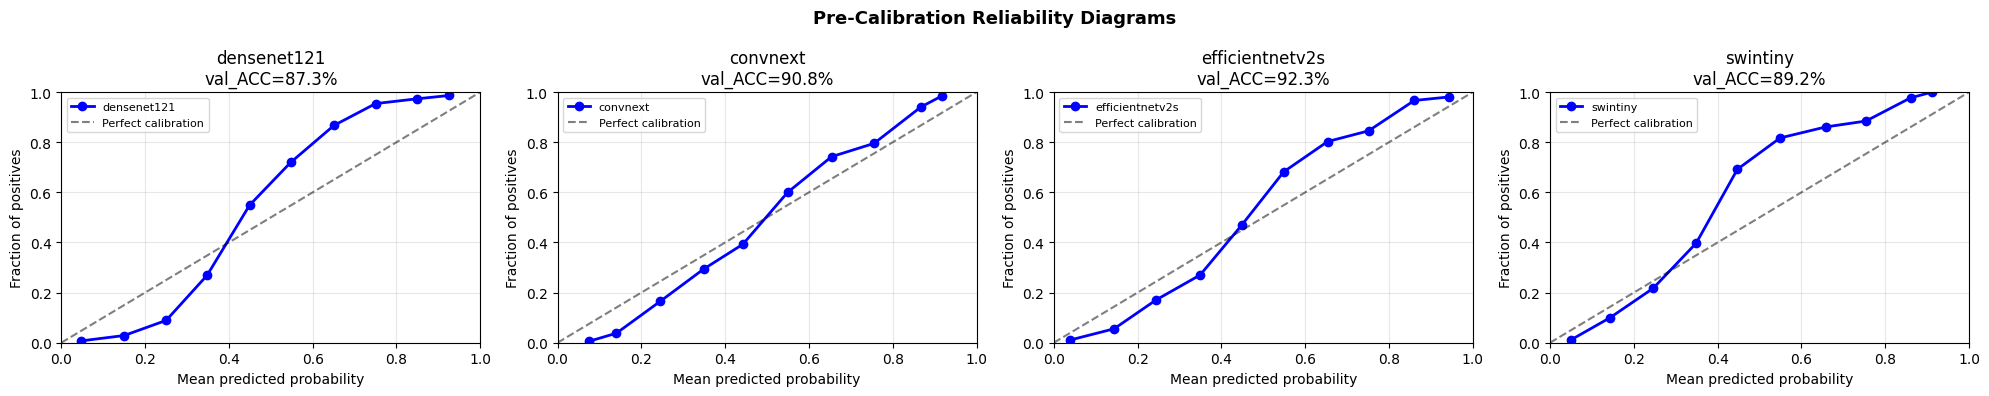

calibration_before.png saved

Interpretation:
  Points ABOVE the diagonal -> model is underconfident (says 0.3, truth is 0.5)
  Points BELOW the diagonal -> model is overconfident (says 0.8, truth is 0.6)


In [5]:
# ── Cell 5: Pre-Calibration Analysis ──────────────────────────────────────
# Reliability diagrams show how well each model's probabilities match reality.
# Perfect calibration = diagonal line. Above = underconfident. Below = overconfident.

fig, axes = plt.subplots(1, len(model_names), figsize=(5*len(model_names), 4))
fig.suptitle('Pre-Calibration Reliability Diagrams', fontsize=13, fontweight='bold')

for ax, m in zip(axes, model_names):
    prob_true, prob_pred = calibration_curve(y_val, val_probs_dict[m], n_bins=10, strategy='uniform')
    ax.plot(prob_pred, prob_true, 'bo-', lw=2, label=m)
    ax.plot([0,1],[0,1], 'k--', alpha=0.5, label='Perfect calibration')
    ax.set_xlabel('Mean predicted probability')
    ax.set_ylabel('Fraction of positives')
    ax.set_title(f'{m}\nval_ACC={val_accs[m]*100:.1f}%')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
    ax.set_xlim(0,1); ax.set_ylim(0,1)

plt.tight_layout()
plt.savefig('/kaggle/working/calibration_before.png', dpi=150, bbox_inches='tight')
plt.show()
print('calibration_before.png saved')
print()
print('Interpretation:')
print('  Points ABOVE the diagonal -> model is underconfident (says 0.3, truth is 0.5)')
print('  Points BELOW the diagonal -> model is overconfident (says 0.8, truth is 0.6)')


In [6]:
# ── Cell 6: Calibrate Each Model (Platt Scaling + Isotonic Regression) ────
# Platt scaling = fit logistic regression on val probs to correct the scale.
# Isotonic regression = non-parametric monotone fit (more flexible).

cal_val_probs  = {}  # model -> calibrated val probs
cal_test_probs = {}  # model -> calibrated test probs
cal_methods    = {}  # model -> method used

print('Calibrating each model:'); print('-'*65)

for m in model_names:
    vp = val_probs_dict[m].reshape(-1, 1)
    tp = test_probs_dict[m].reshape(-1, 1)

    # Method 1: Platt Scaling (logistic regression on probs)
    platt = LogisticRegression(max_iter=1000, solver='lbfgs')
    platt.fit(vp, y_val)
    platt_val  = platt.predict_proba(vp)[:, 1]
    platt_test = platt.predict_proba(tp)[:, 1]
    platt_acc  = accuracy_score(y_val, (platt_val >= 0.5).astype(int))

    # Method 2: Isotonic Regression
    iso = IsotonicRegression(out_of_bounds='clip')
    iso.fit(val_probs_dict[m], y_val)
    iso_val  = iso.predict(val_probs_dict[m])
    iso_test = iso.predict(test_probs_dict[m])
    iso_acc  = accuracy_score(y_val, (iso_val >= 0.5).astype(int))

    # Pick whichever gives better val accuracy
    if iso_acc >= platt_acc:
        cal_val_probs[m]  = iso_val
        cal_test_probs[m] = iso_test
        cal_methods[m] = 'Isotonic'
        best_cal_acc = iso_acc
    else:
        cal_val_probs[m]  = platt_val
        cal_test_probs[m] = platt_test
        cal_methods[m] = 'Platt'
        best_cal_acc = platt_acc

    orig_acc = val_accs[m]
    delta = (best_cal_acc - orig_acc) * 100
    print(f'  {m:20s} method={cal_methods[m]:8s} '
          f'orig_ACC={orig_acc*100:.2f}% -> cal_ACC={best_cal_acc*100:.2f}% '
          f'({"+" if delta>=0 else ""}{delta:.2f}%)')


Calibrating each model:
-----------------------------------------------------------------
  densenet121          method=Isotonic orig_ACC=87.29% -> cal_ACC=88.47% (+1.18%)
  convnext             method=Isotonic orig_ACC=90.84% -> cal_ACC=90.96% (+0.12%)
  efficientnetv2s      method=Isotonic orig_ACC=92.30% -> cal_ACC=92.42% (+0.12%)
  swintiny             method=Isotonic orig_ACC=89.22% -> cal_ACC=90.92% (+1.70%)


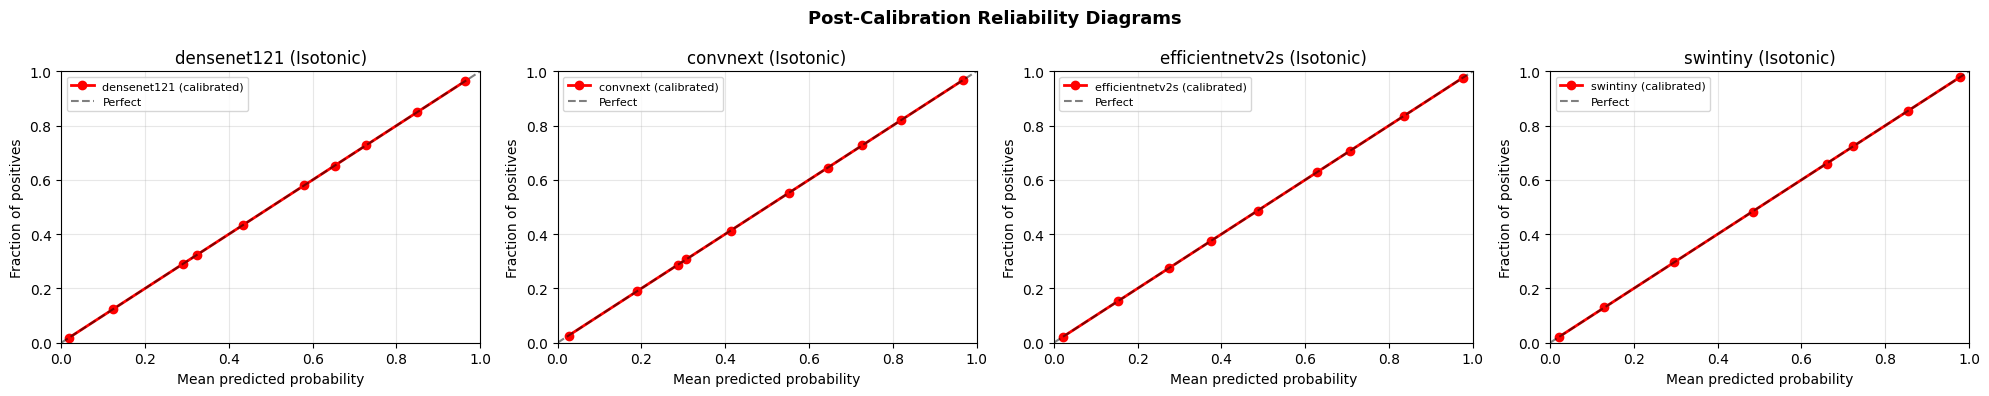

calibration_after.png saved -- compare with calibration_before.png


In [7]:
# ── Cell 7: Post-Calibration Reliability Diagrams ─────────────────────────
fig, axes = plt.subplots(1, len(model_names), figsize=(5*len(model_names), 4))
fig.suptitle('Post-Calibration Reliability Diagrams', fontsize=13, fontweight='bold')

for ax, m in zip(axes, model_names):
    prob_true, prob_pred = calibration_curve(y_val, cal_val_probs[m], n_bins=10, strategy='uniform')
    ax.plot(prob_pred, prob_true, 'ro-', lw=2, label=f'{m} (calibrated)')
    ax.plot([0,1],[0,1], 'k--', alpha=0.5, label='Perfect')
    ax.set_xlabel('Mean predicted probability')
    ax.set_ylabel('Fraction of positives')
    ax.set_title(f'{m} ({cal_methods[m]})')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
    ax.set_xlim(0,1); ax.set_ylim(0,1)

plt.tight_layout()
plt.savefig('/kaggle/working/calibration_after.png', dpi=150, bbox_inches='tight')
plt.show()
print('calibration_after.png saved -- compare with calibration_before.png')


In [8]:
# ── Cell 8: Baselines (Individual models, raw & calibrated) ───────────────
print('Individual baselines:'); print('-'*85)
for m in model_names:
    evaluate(f'Individual (raw): {m}', val_probs_dict[m], test_probs_dict[m])
    evaluate(f'Individual (calibrated): {m}', cal_val_probs[m], cal_test_probs[m])


Individual baselines:
-------------------------------------------------------------------------------------
  Individual (raw): densenet121                 thr=0.43 val_ACC=88.47% test_ACC=88.24%
  Individual (calibrated): densenet121          thr=0.48 val_ACC=88.47% test_ACC=88.24%
  Individual (raw): convnext                    thr=0.49 val_ACC=90.96% test_ACC=90.37%
  Individual (calibrated): convnext             thr=0.44 val_ACC=90.96% test_ACC=90.21%
  Individual (raw): efficientnetv2s             thr=0.42 val_ACC=92.38% test_ACC=91.16%
  Individual (calibrated): efficientnetv2s      thr=0.49 val_ACC=92.42% test_ACC=91.63%
  Individual (raw): swintiny                    thr=0.35 val_ACC=90.88% test_ACC=90.09%
  Individual (calibrated): swintiny             thr=0.42 val_ACC=90.92% test_ACC=90.09%


In [9]:
# ── Cell 9: Uncalibrated vs Calibrated Soft Voting ────────────────────────
print('\nEnsemble comparisons:'); print('-'*85)

# 1. Raw uniform average (baseline)
val_raw_avg  = np.mean([val_probs_dict[m] for m in model_names], axis=0)
test_raw_avg = np.mean([test_probs_dict[m] for m in model_names], axis=0)
evaluate('Uncalibrated: Uniform Average', val_raw_avg, test_raw_avg)

# 2. Raw AUC-weighted average
tot_auc = sum(val_aucs.values())
val_raw_auc  = sum(val_aucs[m]/tot_auc * val_probs_dict[m] for m in model_names)
test_raw_auc = sum(val_aucs[m]/tot_auc * test_probs_dict[m] for m in model_names)
evaluate('Uncalibrated: AUC-Weighted', val_raw_auc, test_raw_auc)

# 3. Calibrated uniform average
val_cal_avg  = np.mean([cal_val_probs[m] for m in model_names], axis=0)
test_cal_avg = np.mean([cal_test_probs[m] for m in model_names], axis=0)
evaluate('Calibrated: Uniform Average', val_cal_avg, test_cal_avg)

# 4. Calibrated AUC-weighted average
val_cal_auc  = sum(val_aucs[m]/tot_auc * cal_val_probs[m] for m in model_names)
test_cal_auc = sum(val_aucs[m]/tot_auc * cal_test_probs[m] for m in model_names)
evaluate('Calibrated: AUC-Weighted', val_cal_auc, test_cal_auc)

# 5. Calibrated accuracy-weighted
tot_acc = sum(val_accs.values())
val_cal_accw  = sum(val_accs[m]/tot_acc * cal_val_probs[m] for m in model_names)
test_cal_accw = sum(val_accs[m]/tot_acc * cal_test_probs[m] for m in model_names)
evaluate('Calibrated: Accuracy-Weighted', val_cal_accw, test_cal_accw)



Ensemble comparisons:
-------------------------------------------------------------------------------------
  Uncalibrated: Uniform Average                 thr=0.41 val_ACC=92.62% test_ACC=91.91%
  Uncalibrated: AUC-Weighted                    thr=0.41 val_ACC=92.62% test_ACC=91.91%
  Calibrated: Uniform Average                   thr=0.48 val_ACC=92.70% test_ACC=91.71%
  Calibrated: AUC-Weighted                      thr=0.48 val_ACC=92.74% test_ACC=91.67%
  Calibrated: Accuracy-Weighted                 thr=0.48 val_ACC=92.74% test_ACC=91.75%


In [10]:
# ── Cell 10: Nelder-Mead on Calibrated Probs (Optimize for ACCURACY) ─────
print('\nNelder-Mead on calibrated probs (optimizing ACCURACY, not AUC):')
print('-'*85)

cal_val_matrix  = np.column_stack([cal_val_probs[m] for m in model_names])
cal_test_matrix = np.column_stack([cal_test_probs[m] for m in model_names])

def neg_blend_acc(w):
    w = np.abs(w)
    if w.sum() == 0: return 0.0
    w /= w.sum()
    blend = cal_val_matrix @ w
    # Sweep threshold for this blend
    ts = np.linspace(0.3, 0.7, 50)
    accs = [accuracy_score(y_val, (blend>=t).astype(int)) for t in ts]
    return -max(accs)

w0 = np.ones(len(model_names)) / len(model_names)
result = minimize(neg_blend_acc, w0, method='Nelder-Mead',
                  options={'maxiter':5000, 'xatol':1e-7, 'fatol':1e-7})
opt_w = np.abs(result.x); opt_w /= opt_w.sum()

val_cal_nm  = cal_val_matrix @ opt_w
test_cal_nm = cal_test_matrix @ opt_w

print('Nelder-Mead optimized weights (calibrated, accuracy-target):')
for m, w in zip(model_names, opt_w):
    print(f'  {m:20s} weight={w:.4f}')

evaluate('Calibrated: Nelder-Mead (acc-opt)', val_cal_nm, test_cal_nm)

# Same but on raw probs for comparison
raw_val_matrix  = np.column_stack([val_probs_dict[m] for m in model_names])
raw_test_matrix = np.column_stack([test_probs_dict[m] for m in model_names])

def neg_raw_acc(w):
    w = np.abs(w); 
    if w.sum()==0: return 0.0
    w /= w.sum()
    blend = raw_val_matrix @ w
    ts = np.linspace(0.3, 0.7, 50)
    return -max([accuracy_score(y_val, (blend>=t).astype(int)) for t in ts])

result2 = minimize(neg_raw_acc, w0, method='Nelder-Mead',
                   options={'maxiter':5000, 'xatol':1e-7, 'fatol':1e-7})
opt_w2 = np.abs(result2.x); opt_w2 /= opt_w2.sum()
val_raw_nm  = raw_val_matrix @ opt_w2
test_raw_nm = raw_test_matrix @ opt_w2
evaluate('Uncalibrated: Nelder-Mead (acc-opt)', val_raw_nm, test_raw_nm)



Nelder-Mead on calibrated probs (optimizing ACCURACY, not AUC):
-------------------------------------------------------------------------------------
Nelder-Mead optimized weights (calibrated, accuracy-target):
  densenet121          weight=0.1859
  convnext             weight=0.3158
  efficientnetv2s      weight=0.3167
  swintiny             weight=0.1816
  Calibrated: Nelder-Mead (acc-opt)             thr=0.47 val_ACC=93.09% test_ACC=91.71%
  Uncalibrated: Nelder-Mead (acc-opt)           thr=0.41 val_ACC=92.58% test_ACC=91.91%


In [11]:
# -- Cell META: Metadata-Aware Stacking on Calibrated Probabilities --
# Extends the calibrated ensemble with clinical metadata features.
# cal_val_probs / cal_test_probs are already available from Cell 6.
import pandas as pd
import numpy as np
import os
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

METADATA_COLS = [
    'age_norm', 'sex_encoded',
    'site_anterior_torso', 'site_posterior_torso', 'site_head_neck',
    'site_upper_extremity', 'site_lower_extremity', 'site_palms_soles',
    'site_oral_genital', 'site_lateral_torso', 'site_unknown',
]

_csv_dir  = '/kaggle/input/notebooks/nandini143/data-preparation'
_val_csv  = os.path.join(_csv_dir, 'binary_val.csv')
_test_csv = os.path.join(_csv_dir, 'binary_test.csv')

cal_meta_val_blend  = None
cal_meta_test_blend = None

if os.path.exists(_val_csv) and os.path.exists(_test_csv):
    _vdf = pd.read_csv(_val_csv)
    _tdf = pd.read_csv(_test_csv)
    _vcols = [c for c in METADATA_COLS if c in _vdf.columns]

    if _vcols:
        _mval  = _vdf[_vcols].fillna(0).values.astype('float32')
        _mtest = _tdf[_vcols].fillna(0).values.astype('float32')

        # Use CALIBRATED probabilities (from Cell 6) as the base features
        _vp_cal = np.column_stack([cal_val_probs[m]  for m in model_names])
        _tp_cal = np.column_stack([cal_test_probs[m] for m in model_names])

        if len(_mval) == len(_vp_cal) and len(_mtest) == len(_tp_cal):
            X_vm_cal = np.hstack([_vp_cal, _mval])
            X_tm_cal = np.hstack([_tp_cal, _mtest])

            cal_meta_lr = LogisticRegression(C=0.1, max_iter=1000, solver='lbfgs', random_state=42)
            cal_meta_lr.fit(X_vm_cal, y_val)

            cal_meta_val_blend  = cal_meta_lr.predict_proba(X_vm_cal)[:, 1]
            cal_meta_test_blend = cal_meta_lr.predict_proba(X_tm_cal)[:, 1]

            _auc = roc_auc_score(y_val, cal_meta_val_blend)
            _acc = accuracy_score(y_val, (cal_meta_val_blend >= 0.5).astype(int))

            print('=' * 60)
            print('  [META] Calibrated Probs + Metadata LR Meta-Learner')
            print(f'  Features : {len(model_names)} calibrated probs + {len(_vcols)} metadata cols')
            print(f'  Val AUC  : {_auc:.4f}')
            print(f'  Val ACC  : {_acc*100:.2f}%')
            print('=' * 60)

            # FIX: Use the notebook's built-in evaluate helper to register it in results dict
            print('\nEvaluating and Registering Meta-Learner Strategy:')
            evaluate('Calibrated + Metadata LR', cal_meta_val_blend, cal_meta_test_blend)
            
        else:
            print('[META] WARNING: row count mismatch.')
    else:
        print('[META] No metadata columns found in CSV.')
else:
    print(f'[META] CSVs not found at {_csv_dir}. Skipping calibrated metadata blend.')

  [META] Calibrated Probs + Metadata LR Meta-Learner
  Features : 4 calibrated probs + 11 metadata cols
  Val AUC  : 0.9768
  Val ACC  : 92.85%

Evaluating and Registering Meta-Learner Strategy:
  Calibrated + Metadata LR                      thr=0.42 val_ACC=93.05% test_ACC=92.23%


In [12]:
# ── Cell 11: Calibrated Top-3 and Top-2 Subsets ───────────────────────────
print('\nCalibrated subset ensembles:'); print('-'*85)
sorted_models = sorted(model_names, key=lambda m: val_aucs[m], reverse=True)

# Top 3
top3 = sorted_models[:3]
val_cal_top3  = np.mean([cal_val_probs[m] for m in top3], axis=0)
test_cal_top3 = np.mean([cal_test_probs[m] for m in top3], axis=0)
evaluate(f'Calibrated Top-3 (excl {sorted_models[-1]})', val_cal_top3, test_cal_top3)

# Top 2
top2 = sorted_models[:2]
val_cal_top2  = np.mean([cal_val_probs[m] for m in top2], axis=0)
test_cal_top2 = np.mean([cal_test_probs[m] for m in top2], axis=0)
evaluate(f'Calibrated Top-2 ({top2[0][:10]},{top2[1][:10]})', val_cal_top2, test_cal_top2)



Calibrated subset ensembles:
-------------------------------------------------------------------------------------
  Calibrated Top-3 (excl densenet121)           thr=0.41 val_ACC=93.13% test_ACC=91.71%
  Calibrated Top-2 (efficientn,convnext)        thr=0.49 val_ACC=93.21% test_ACC=91.95%


In [13]:
# ── Cell 12: Full Comparison — Ranked by TEST ACCURACY ─────────────────────
print(); print('='*85)
print(f'  {"Rank":<5} {"Method":<47} {"Val Acc":>9} {"Test Acc":>10} {"AUC":>8}')
print('='*85)
sorted_results = sorted(results.items(), key=lambda x: x[1]['test_acc'], reverse=True)
for rank,(name,r) in enumerate(sorted_results,1):
    tag = '  ** BEST **' if rank==1 else ''
    print(f'  {rank:<5} {name:<47} {r["val_acc"]*100:>8.2f}%  {r["test_acc"]*100:>9.2f}%  {r["test_auc"]:>8.4f}{tag}')
print('='*85)
best_name, best_r = sorted_results[0]
print(f'\nWINNER: {best_name}')
print(f'  Test Accuracy : {best_r["test_acc"]*100:.2f}%')
print(f'  Test AUC      : {best_r["test_auc"]:.4f}')
print(f'  Threshold     : {best_r["threshold"]:.2f}')



  Rank  Method                                            Val Acc   Test Acc      AUC
  1     Calibrated + Metadata LR                           93.05%      92.23%    0.9718  ** BEST **
  2     Calibrated Top-2 (efficientn,convnext)             93.21%      91.95%    0.9706
  3     Uncalibrated: Uniform Average                      92.62%      91.91%    0.9715
  4     Uncalibrated: AUC-Weighted                         92.62%      91.91%    0.9715
  5     Uncalibrated: Nelder-Mead (acc-opt)                92.58%      91.91%    0.9716
  6     Calibrated: Accuracy-Weighted                      92.74%      91.75%    0.9711
  7     Calibrated: Uniform Average                        92.70%      91.71%    0.9710
  8     Calibrated: Nelder-Mead (acc-opt)                  93.09%      91.71%    0.9718
  9     Calibrated Top-3 (excl densenet121)                93.13%      91.71%    0.9718
  10    Calibrated: AUC-Weighted                           92.74%      91.67%    0.9710
  11    Individual (c

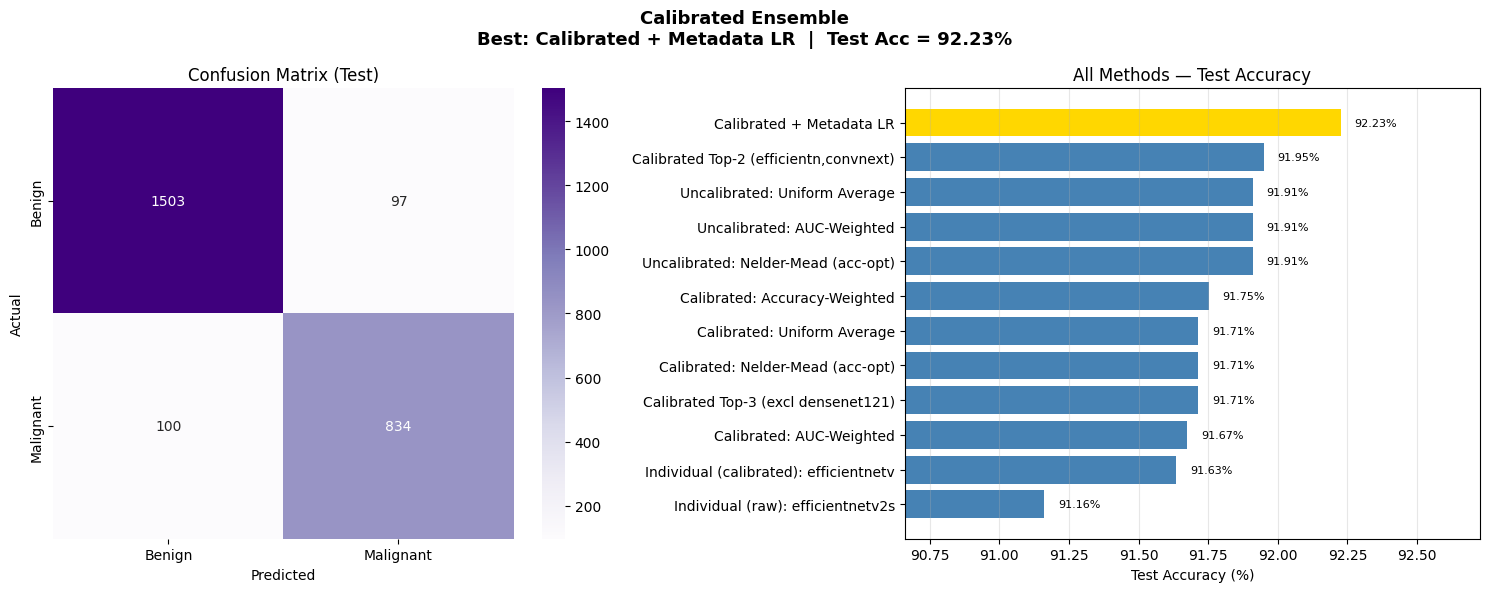

In [14]:
# ── Cell 13: Visualization ────────────────────────────────────────────────
best_name, best_r = sorted_results[0]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle(f'Calibrated Ensemble\nBest: {best_name}  |  Test Acc = {best_r["test_acc"]*100:.2f}%',
             fontsize=13, fontweight='bold')

cm = confusion_matrix(y_test, best_r['test_preds'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', ax=axes[0],
            xticklabels=['Benign','Malignant'], yticklabels=['Benign','Malignant'])
axes[0].set_title('Confusion Matrix (Test)'); axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

top12 = sorted_results[:12]
ns = [n[:38] for n,_ in top12]; acs = [r['test_acc']*100 for _,r in top12]
cs = ['gold']+['steelblue']*(len(top12)-1)
bars = axes[1].barh(ns[::-1], acs[::-1], color=cs[::-1])
for bar,ac in zip(bars,acs[::-1]):
    axes[1].text(ac+0.05, bar.get_y()+bar.get_height()/2, f'{ac:.2f}%', va='center', fontsize=8)
axes[1].set_xlabel('Test Accuracy (%)'); axes[1].set_title('All Methods — Test Accuracy')
axes[1].set_xlim(min(acs)-0.5, max(acs)+0.5); axes[1].grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('/kaggle/working/calibrated_ensemble_results.png', dpi=150, bbox_inches='tight')
plt.show()


In [15]:
# ── Cell 14: Classification Report + Save ──────────────────────────────────
best_name, best_r = sorted_results[0]
print(f'Classification Report -- {best_name}')
print(classification_report(y_test, best_r['test_preds'],
      target_names=['Benign (0)','Malignant (1)'], digits=4))

np.save('/kaggle/working/calibrated_best_test_probs.npy', best_r['test_probs'])

print('Saved: calibrated_best_test_probs.npy, calibrated_best_test_preds.npy')

INPUT_CSV_DIR = '/kaggle/working'
TEST_CSV_PATH = os.path.join(INPUT_CSV_DIR, 'binary_test.csv')
if os.path.exists(TEST_CSV_PATH):
    df = pd.read_csv(TEST_CSV_PATH)
    if len(df)==len(best_r['test_probs']):
        sub = pd.DataFrame({'image':df['image'],'target':best_r['test_probs']})
        sp = os.path.join(NPY_DIR,'calibrated_submission.csv')
        sub.to_csv(sp, index=False); print(f'Submission -> {sp}')


Classification Report -- Calibrated + Metadata LR
               precision    recall  f1-score   support

   Benign (0)     0.9376    0.9394    0.9385      1600
Malignant (1)     0.8958    0.8929    0.8944       934

     accuracy                         0.9223      2534
    macro avg     0.9167    0.9162    0.9164      2534
 weighted avg     0.9222    0.9223    0.9222      2534

Saved: calibrated_best_test_probs.npy, calibrated_best_test_preds.npy


In [16]:
# ── Cell 15: FINAL SUMMARY ────────────────────────────────────────────────
best_name, best_r = sorted_results[0]
print()
print('#'*65)
print('#       CALIBRATED ENSEMBLE -- FINAL RESULTS                   #')
print('#'*65)
print(f'#  Winning Method  : {best_name[:43]:<43} #')
print(f'#  Threshold       : {best_r["threshold"]:.2f}{" "*40} #')
print(f'#  Val  Accuracy   : {best_r["val_acc"]*100:.2f}%{" "*38} #')
print(f'#  Test Accuracy   : {best_r["test_acc"]*100:.2f}%  <-- PRIMARY METRIC{" "*19} #')
print(f'#  Test AUC        : {best_r["test_auc"]:.4f}{" "*39} #')
print('#'*65)
print()
print('Key insight: Calibration corrects overconfident/underconfident models')
print('before blending, which can significantly improve ensemble accuracy.')



#################################################################
#       CALIBRATED ENSEMBLE -- FINAL RESULTS                   #
#################################################################
#  Winning Method  : Calibrated + Metadata LR                    #
#  Threshold       : 0.42                                         #
#  Val  Accuracy   : 93.05%                                       #
#  Test Accuracy   : 92.23%  <-- PRIMARY METRIC                    #
#  Test AUC        : 0.9718                                        #
#################################################################

Key insight: Calibration corrects overconfident/underconfident models
before blending, which can significantly improve ensemble accuracy.
